In [2]:
import pandas as pd

df = pd.read_csv("data/accepted_2007_to_2018Q4.csv.gz", low_memory=False)
print(df.shape)
df.head()

(2260701, 151)


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
import os
print(os.getcwd())
print(os.listdir("."))

/home/PES1UG24CS554/lendingclub-loan-default
['.gitignore', '01_explore.ipynb', 'requirements.txt', 'src', 'README.md', '.git', 'data', 'notebooks', '.ipynb_checkpoints', 'venv']


In [4]:
print(df.shape)
print(df["loan_status"].value_counts())

df["issue_year"] = pd.to_datetime(df["issue_d"], format="%b-%Y").dt.year
print(df["issue_year"].value_counts().sort_index())

(2260701, 151)
loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64
issue_year
2007.0       603
2008.0      2393
2009.0      5281
2010.0     12537
2011.0     21721
2012.0     53367
2013.0    134814
2014.0    235629
2015.0    421095
2016.0    434407
2017.0    443579
2018.0    495242
Name: count, dtype: int64


/tmp/ipykernel_44402/1381989103.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["issue_year"] = pd.to_datetime(df["issue_d"], format="%b-%Y").dt.year


In [5]:
print(df.shape)
print(df["loan_status"].value_counts())

df["issue_year"] = pd.to_datetime(df["issue_d"], format="%b-%Y").dt.year
print(df["issue_year"].value_counts().sort_index())

(2260701, 152)
loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64
issue_year
2007.0       603
2008.0      2393
2009.0      5281
2010.0     12537
2011.0     21721
2012.0     53367
2013.0    134814
2014.0    235629
2015.0    421095
2016.0    434407
2017.0    443579
2018.0    495242
Name: count, dtype: int64


In [6]:
# 1. Keep only finalized loans we can label
keep = ["Fully Paid", "Charged Off", "Default"]
data = df[df["loan_status"].isin(keep)].copy()

# 2. Keep loans issued 2012-2015 (same as the paper)
data = data[data["issue_year"].between(2012, 2015)].copy()

# 3. Create target: 1 = Fully Paid, 0 = Charged Off / Default
data["target"] = (data["loan_status"] == "Fully Paid").astype(int)

print(data.shape)
print(data["target"].value_counts())
print(data["target"].value_counts(normalize=True))

(786820, 153)
target
1    640186
0    146634
Name: count, dtype: int64
target
1    0.813637
0    0.186363
Name: proportion, dtype: float64


In [7]:
del df
data.to_pickle("data/loans_2012_2015.pkl")

In [8]:
import numpy as np

# 1. Drop columns that leak the outcome (known only after the loan ends)
leak = [
    "total_pymnt", "total_pymnt_inv", "total_rec_prncp", "total_rec_int",
    "total_rec_late_fee", "recoveries", "collection_recovery_fee",
    "last_pymnt_d", "last_pymnt_amnt", "next_pymnt_d", "last_credit_pull_d",
    "last_fico_range_high", "last_fico_range_low", "out_prncp", "out_prncp_inv",
    "debt_settlement_flag", "debt_settlement_flag_date", "settlement_status",
    "settlement_date", "settlement_amount", "settlement_percentage",
    "settlement_term", "hardship_flag", "pymnt_plan", "funded_amnt",
    "funded_amnt_inv", "loan_status",
]
leak = [c for c in leak if c in data.columns]

# 2. Drop IDs and free-text columns
ids_text = ["id", "member_id", "url", "desc", "title", "emp_title",
            "zip_code", "issue_year"]
ids_text = [c for c in ids_text if c in data.columns]

data = data.drop(columns=leak + ids_text)

# 3. Drop columns that are more than 50% empty
missing = data.isna().mean()
sparse = missing[missing > 0.5].index.tolist()
sparse = [c for c in sparse if c != "target"]
data = data.drop(columns=sparse)

# 4. Drop columns with only one unique value
const = [c for c in data.columns if data[c].nunique() <= 1]
data = data.drop(columns=const)

print(data.shape)
print("Dropped leakage:", len(leak), "| sparse:", len(sparse), "| constant:", len(const))
print(data.dtypes.value_counts())

(786820, 67)
Dropped leakage: 27 | sparse: 49 | constant: 2
float64    54
str        12
int64       1
Name: count, dtype: int64


In [10]:
obj_cols = data.select_dtypes(include="object").columns.tolist()
print(obj_cols)
print(data[obj_cols].nunique())


/tmp/ipykernel_44402/4222183847.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = data.select_dtypes(include="object").columns.tolist()


['term', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'verification_status', 'issue_d', 'purpose', 'addr_state', 'earliest_cr_line', 'initial_list_status', 'application_type']
term                     2
grade                    7
sub_grade               35
emp_length              11
home_ownership           6
verification_status      3
issue_d                 48
purpose                 14
addr_state              51
earliest_cr_line       694
initial_list_status      2
application_type         2
dtype: int64


In [11]:
import pandas as pd

# 1. Convert earliest_cr_line to "years of credit history" (using issue_d as reference)
issue = pd.to_datetime(data["issue_d"], format="%b-%Y")
early = pd.to_datetime(data["earliest_cr_line"], format="%b-%Y")
data["credit_history_years"] = (issue - early).dt.days / 365.25
data = data.drop(columns=["issue_d", "earliest_cr_line"])

# 2. Fill missing numeric values with the median
num_cols = data.select_dtypes(include="number").columns.drop("target")
print("Columns with missing values:", (data[num_cols].isna().sum() > 0).sum())
data[num_cols] = data[num_cols].fillna(data[num_cols].median())

# 3. One-hot encode the remaining text columns
cat_cols = data.select_dtypes(exclude="number").columns.tolist()
data = pd.get_dummies(data, columns=cat_cols, drop_first=True)

print(data.shape)
print(data.isna().sum().sum(), "missing values left")

Columns with missing values: 36
(786820, 179)
0 missing values left


In [12]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["target"])
y = data["target"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(X_train.shape, X_val.shape, X_test.shape)
print(y_train.mean(), y_val.mean(), y_test.mean())

(550774, 178) (118023, 178) (118023, 178)
0.8136368092901989 0.813638019708023 0.813638019708023


In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

lr = LogisticRegression(class_weight="balanced", max_iter=1000)
lr.fit(X_train_s, y_train)

pred = lr.predict(X_val_s)
print(confusion_matrix(y_val, pred))
print(classification_report(y_val, pred, target_names=["Default", "Paid"]))

[[14687  7308]
 [32864 63164]]
              precision    recall  f1-score   support

     Default       0.31      0.67      0.42     21995
        Paid       0.90      0.66      0.76     96028

    accuracy                           0.66    118023
   macro avg       0.60      0.66      0.59    118023
weighted avg       0.79      0.66      0.70    118023



In [14]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

rf = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=50,
                            class_weight="balanced", n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
print("RANDOM FOREST")
print(classification_report(y_val, rf.predict(X_val), target_names=["Default", "Paid"]))

hgb = HistGradientBoostingClassifier(class_weight="balanced", random_state=42)
hgb.fit(X_train, y_train)
print("GRADIENT BOOSTING")
print(classification_report(y_val, hgb.predict(X_val), target_names=["Default", "Paid"]))

RANDOM FOREST
              precision    recall  f1-score   support

     Default       0.30      0.67      0.42     21995
        Paid       0.90      0.65      0.75     96028

    accuracy                           0.65    118023
   macro avg       0.60      0.66      0.58    118023
weighted avg       0.78      0.65      0.69    118023

GRADIENT BOOSTING
              precision    recall  f1-score   support

     Default       0.31      0.68      0.43     21995
        Paid       0.90      0.66      0.76     96028

    accuracy                           0.66    118023
   macro avg       0.61      0.67      0.59    118023
weighted avg       0.79      0.66      0.70    118023



In [15]:
from sklearn.metrics import roc_auc_score, precision_recall_curve
import numpy as np

for name, model, Xv in [("LogReg", lr, X_val_s), ("RandomForest", rf, X_val), ("GradBoost", hgb, X_val)]:
    p = model.predict_proba(Xv)[:, 1]          # probability of "Paid"
    print(name, "AUC:", round(roc_auc_score(y_val, p), 4))

# Best threshold for the Default class using gradient boosting
p_def = 1 - hgb.predict_proba(X_val)[:, 1]     # probability of "Default"
prec, rec, thr = precision_recall_curve(1 - y_val, p_def)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best = np.argmax(f1[:-1])
print("Best threshold:", thr[best], "| precision:", prec[best], "| recall:", rec[best], "| F1:", f1[best])

LogReg AUC: 0.7246
RandomForest AUC: 0.7189
GradBoost AUC: 0.7302
Best threshold: 0.5447042369611707 | precision: 0.33875977017443965 | recall: 0.5950897931348034 | F1: 0.4317450888454744


In [16]:
from sklearn.metrics import classification_report, roc_auc_score
import pandas as pd

thr_best = 0.5447
p_def_test = 1 - hgb.predict_proba(X_test)[:, 1]
pred_test = (p_def_test < thr_best).astype(int)   # 1 = Paid, 0 = Default (flag Default if p_def >= thr)
pred_test = 1 - (p_def_test >= thr_best).astype(int)

print("TEST AUC:", round(roc_auc_score(y_test, 1 - p_def_test), 4))
print(classification_report(y_test, pred_test, target_names=["Default", "Paid"]))

# Feature importance via permutation on a validation sample
from sklearn.inspection import permutation_importance
idx = X_val.sample(20000, random_state=42).index
r = permutation_importance(hgb, X_val.loc[idx], y_val.loc[idx], n_repeats=3,
                           random_state=42, scoring="roc_auc", n_jobs=-1)
imp = pd.Series(r.importances_mean, index=X_val.columns).sort_values(ascending=False)
print(imp.head(10))

TEST AUC: 0.7316
              precision    recall  f1-score   support

     Default       0.34      0.59      0.43     21995
        Paid       0.89      0.73      0.80     96028

    accuracy                           0.71    118023
   macro avg       0.61      0.66      0.62    118023
weighted avg       0.79      0.71      0.73    118023

int_rate                0.058447
term_ 60 months         0.030470
dti                     0.006791
acc_open_past_24mths    0.006341
annual_inc              0.005590
loan_amnt               0.004187
total_bc_limit          0.002569
credit_history_years    0.002162
home_ownership_RENT     0.002035
fico_range_low          0.001923
dtype: float64


In [17]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

raw = pd.read_pickle("data/loans_2012_2015.pkl")   # use "../data/..." if needed
raw = raw.sample(300000, random_state=1)

LEAK = ["total_pymnt","total_pymnt_inv","total_rec_prncp","total_rec_int",
 "total_rec_late_fee","recoveries","collection_recovery_fee","last_pymnt_d",
 "last_pymnt_amnt","next_pymnt_d","last_credit_pull_d","last_fico_range_high",
 "last_fico_range_low","out_prncp","out_prncp_inv","debt_settlement_flag",
 "debt_settlement_flag_date","settlement_status","settlement_date",
 "settlement_amount","settlement_percentage","settlement_term","hardship_flag",
 "pymnt_plan","funded_amnt","funded_amnt_inv","loan_status"]
IDS = ["id","member_id","url","desc","title","emp_title","zip_code","issue_year"]

def run(sparse_thr=0.5, impute="median", drop_cols=(), ratios=False, flags=False):
    d = raw.drop(columns=[c for c in LEAK + IDS if c in raw.columns])
    miss = d.isna().mean()
    d = d.drop(columns=[c for c in miss[miss > sparse_thr].index if c != "target"])
    d = d.drop(columns=[c for c in d.columns if d[c].nunique() <= 1])

    issue = pd.to_datetime(d["issue_d"], format="%b-%Y")
    early = pd.to_datetime(d["earliest_cr_line"], format="%b-%Y")
    d["credit_history_years"] = (issue - early).dt.days / 365.25
    d = d.drop(columns=["issue_d", "earliest_cr_line"])
    d = d.drop(columns=[c for c in drop_cols if c in d.columns])

    if ratios:
        d["loan_to_income"] = d["loan_amnt"] / (d["annual_inc"] + 1)
        d["installment_to_income"] = d["installment"] * 12 / (d["annual_inc"] + 1)
        d["revol_bal_to_income"] = d["revol_bal"] / (d["annual_inc"] + 1)

    num = d.select_dtypes(include="number").columns.drop("target")
    if flags:
        for c in num:
            if d[c].isna().any():
                d[c + "_missing"] = d[c].isna().astype(int)
    if impute == "median":
        d[num] = d[num].fillna(d[num].median())
    elif impute == "zero":
        d[num] = d[num].fillna(0)
    # impute == "none": leave NaN, gradient boosting handles it natively

    cat = d.select_dtypes(exclude="number").columns.tolist()
    d = pd.get_dummies(d, columns=cat, drop_first=True)

    X, y = d.drop(columns=["target"]), d["target"]
    Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    m = HistGradientBoostingClassifier(random_state=42).fit(Xtr, ytr)
    return round(roc_auc_score(yva, m.predict_proba(Xva)[:, 1]), 4), X.shape[1]

experiments = {
 "baseline (median, thr 0.5)":        dict(),
 "fill with zero":                    dict(impute="zero"),
 "leave NaN (no filling)":            dict(impute="none"),
 "median + missing flags":            dict(flags=True),
 "keep more columns (thr 0.8)":       dict(sparse_thr=0.8, impute="none"),
 "add income ratios":                 dict(ratios=True),
 "drop grade/sub_grade/int_rate":     dict(drop_cols=["grade","sub_grade","int_rate"]),
 "drop addr_state":                   dict(drop_cols=["addr_state"]),
}
for name, cfg in experiments.items():
    auc, n = run(**cfg)
    print(f"{name:35s} AUC={auc}  features={n}")

baseline (median, thr 0.5)          AUC=0.7236  features=177
fill with zero                      AUC=0.7235  features=177
leave NaN (no filling)              AUC=0.7242  features=177
median + missing flags              AUC=0.7235  features=213
keep more columns (thr 0.8)         AUC=0.7239  features=181
add income ratios                   AUC=0.7235  features=180
drop grade/sub_grade/int_rate       AUC=0.7193  features=136
drop addr_state                     AUC=0.7216  features=128


In [18]:
def run2(zip_te=False, emp_top=False, text_len=False, thr=0.8):
    d = raw.drop(columns=[c for c in LEAK + ["id","member_id","url","issue_year"] if c in raw.columns])
    miss = d.isna().mean()
    keep_text = ["desc","title","emp_title","zip_code"]
    d = d.drop(columns=[c for c in miss[miss > thr].index if c not in keep_text + ["target"]])
    d = d.drop(columns=[c for c in d.columns if d[c].nunique() <= 1])

    d["credit_history_years"] = (pd.to_datetime(d["issue_d"], format="%b-%Y")
                                 - pd.to_datetime(d["earliest_cr_line"], format="%b-%Y")).dt.days / 365.25
    d = d.drop(columns=["issue_d", "earliest_cr_line"])

    if text_len:
        d["title_len"] = d["title"].fillna("").str.len()
        d["desc_len"] = d["desc"].fillna("").str.len()
        d["emp_title_missing"] = d["emp_title"].isna().astype(int)
    if emp_top:
        top = d["emp_title"].str.lower().value_counts().head(30).index
        d["emp_group"] = d["emp_title"].str.lower().where(d["emp_title"].str.lower().isin(top), "other")
    zip_col = d["zip_code"].copy()
    d = d.drop(columns=[c for c in keep_text if c in d.columns] + (["emp_group"] if False else []))
    # (emp_group, if created, stays as a normal categorical column)

    cat = d.select_dtypes(exclude="number").columns.tolist()
    d = pd.get_dummies(d, columns=cat, drop_first=True)
    X, y = d.drop(columns=["target"]), d["target"]
    Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    if zip_te:  # target-encode zip using TRAIN rows only, so nothing leaks
        z_tr = zip_col.loc[Xtr.index]
        te = ytr.groupby(z_tr).mean()
        Xtr = Xtr.assign(zip_rate=z_tr.map(te).fillna(ytr.mean()).values)
        Xva = Xva.assign(zip_rate=zip_col.loc[Xva.index].map(te).fillna(ytr.mean()).values)

    m = HistGradientBoostingClassifier(random_state=42).fit(Xtr, ytr)
    return round(roc_auc_score(yva, m.predict_proba(Xva)[:, 1]), 4), Xtr.shape[1]

tests = {
  "reference (thr 0.8)":        dict(),
  "+ text lengths":             dict(text_len=True),
  "+ top-30 job titles":        dict(emp_top=True),
  "+ zip target encoding":      dict(zip_te=True),
  "all three":                  dict(text_len=True, emp_top=True, zip_te=True),
}
for name, cfg in tests.items():
    auc, n = run2(**cfg)
    print(f"{name:30s} AUC={auc}  features={n}")

reference (thr 0.8)            AUC=0.7239  features=181
+ text lengths                 AUC=0.7256  features=184
+ top-30 job titles            AUC=0.724  features=211
+ zip target encoding          AUC=0.7234  features=182
all three                      AUC=0.7247  features=215


{'AUC': 0.7255, 'acc': 0.66, 'w_prec': 0.787, 'w_rec': 0.66, 'def_P': np.float64(0.31), 'def_R': np.float64(0.67), 'def_F1': np.float64(0.42), 'n_feat': 1078, 'setup': '1 leakage-free (ours)'}
{'AUC': 0.9402, 'acc': 0.855, 'w_prec': 0.901, 'w_rec': 0.855, 'def_P': np.float64(0.57), 'def_R': np.float64(0.91), 'def_F1': np.float64(0.7), 'n_feat': 1080, 'setup': '2 + last_fico'}
{'AUC': 0.9998, 'acc': 0.999, 'w_prec': 0.999, 'w_rec': 0.999, 'def_P': np.float64(1.0), 'def_R': np.float64(1.0), 'def_F1': np.float64(1.0), 'n_feat': 1090, 'setup': '3 + payments'}
{'AUC': 0.9999, 'acc': 0.999, 'w_prec': 0.999, 'w_rec': 0.999, 'def_P': np.float64(1.0), 'def_R': np.float64(1.0), 'def_F1': np.float64(1.0), 'n_feat': 1092, 'setup': '4 + dates'}
{'AUC': 0.9999, 'acc': 0.999, 'w_prec': 0.999, 'w_rec': 0.999, 'def_P': np.float64(1.0), 'def_R': np.float64(1.0), 'def_F1': np.float64(1.0), 'n_feat': 1093, 'setup': '5 + settlement (paper-style)'}
                                 AUC    acc  w_prec  w_rec 

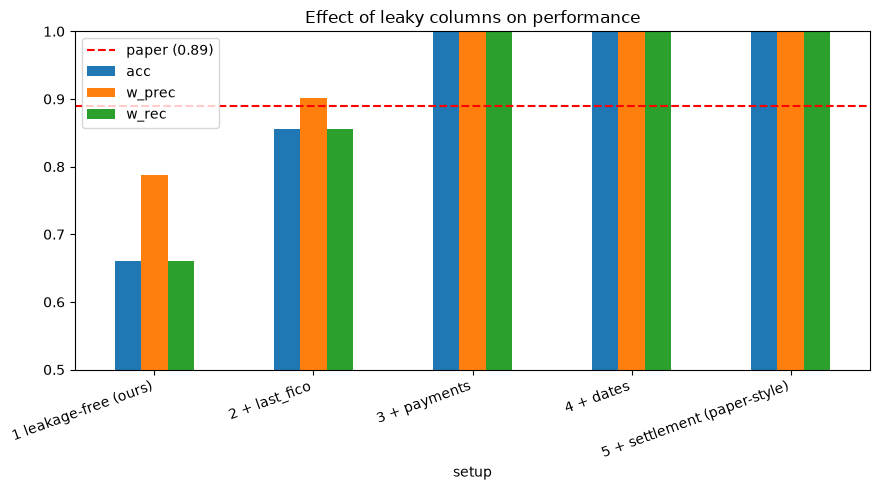

In [19]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

GROUPS = {
 "last_fico": ["last_fico_range_high", "last_fico_range_low"],
 "payments":  ["total_pymnt","total_pymnt_inv","total_rec_prncp","total_rec_int",
               "total_rec_late_fee","recoveries","collection_recovery_fee",
               "last_pymnt_amnt","out_prncp","out_prncp_inv"],
 "dates":     ["last_pymnt_d","next_pymnt_d","last_credit_pull_d"],
 "settle":    ["debt_settlement_flag","debt_settlement_flag_date","settlement_status",
               "settlement_date","settlement_amount","settlement_percentage",
               "settlement_term","hardship_flag","pymnt_plan"],
}
ALL_LEAK = sum(GROUPS.values(), [])
DATE_COLS = ["issue_d","earliest_cr_line","last_pymnt_d","next_pymnt_d",
             "last_credit_pull_d","debt_settlement_flag_date","settlement_date"]

def run3(groups=()):
    d = raw.drop(columns=[c for c in ["id","member_id","url","desc","title",
                                      "emp_title","issue_year","loan_status"] if c in raw.columns])
    keep = sum((GROUPS[g] for g in groups), [])
    d = d.drop(columns=[c for c in ALL_LEAK if c in d.columns and c not in keep])
    miss = d.isna().mean()
    d = d.drop(columns=[c for c in miss[miss > 0.5].index if c != "target"])
    d = d.drop(columns=[c for c in d.columns if d[c].nunique() <= 1])
    for c in DATE_COLS:                      # dates -> days since epoch, as in the paper
        if c in d.columns:
            d[c] = (pd.to_datetime(d[c], format="%b-%Y", errors="coerce")
                    - pd.Timestamp("1970-01-01")).dt.days
    num = d.select_dtypes(include="number").columns.drop("target")
    d[num] = d[num].fillna(d[num].median())
    cat = d.select_dtypes(exclude="number").columns.tolist()   # includes zip_code
    d = pd.get_dummies(d, columns=cat, drop_first=True)
    X, y = d.drop(columns=["target"]), d["target"]
    Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    m = HistGradientBoostingClassifier(class_weight="balanced", random_state=42).fit(Xtr, ytr)
    p = m.predict_proba(Xva)[:, 1]
    pred = (p >= 0.5).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(yva, pred, labels=[0], zero_division=0)
    pw, rw, _, _ = precision_recall_fscore_support(yva, pred, average="weighted")
    return dict(AUC=round(roc_auc_score(yva, p), 4), acc=round(accuracy_score(yva, pred), 3),
                w_prec=round(pw, 3), w_rec=round(rw, 3),
                def_P=round(pr[0], 2), def_R=round(rc[0], 2), def_F1=round(f1[0], 2),
                n_feat=X.shape[1])

import matplotlib.pyplot as plt

ladder = {
 "1 leakage-free (ours)":   (),
 "2 + last_fico":           ("last_fico",),
 "3 + payments":            ("last_fico","payments"),
 "4 + dates":               ("last_fico","payments","dates"),
 "5 + settlement (paper-style)": ("last_fico","payments","dates","settle"),
}
rows = []
for name, g in ladder.items():
    r = run3(g); r["setup"] = name
    rows.append(r); print(r)

res = pd.DataFrame(rows).set_index("setup")
print(res[["AUC","acc","w_prec","w_rec","def_F1","n_feat"]])

ax = res[["acc","w_prec","w_rec"]].plot(kind="bar", figsize=(9,5), ylim=(0.5,1.0))
ax.axhline(0.89, color="red", linestyle="--", label="paper (0.89)")
ax.set_title("Effect of leaky columns on performance")
ax.legend(); plt.xticks(rotation=20, ha="right"); plt.tight_layout()
plt.savefig("leakage_ladder.png", dpi=150)
plt.show()

In [20]:
print("SPARSE (>50% empty):")
print(sparse)
print("\nCONSTANT:")
print(const)

SPARSE (>50% empty):
['mths_since_last_delinq', 'mths_since_last_record', 'mths_since_last_major_derog', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m', 'mths_since_recent_bc_dlq', 'mths_since_recent_revol_delinq', 'revol_bal_joint', 'sec_app_fico_range_low', 'sec_app_fico_range_high', 'sec_app_earliest_cr_line', 'sec_app_inq_last_6mths', 'sec_app_mort_acc', 'sec_app_open_acc', 'sec_app_revol_util', 'sec_app_open_act_il', 'sec_app_num_rev_accts', 'sec_app_chargeoff_within_12_mths', 'sec_app_collections_12_mths_ex_med', 'sec_app_mths_since_last_major_derog', 'hardship_type', 'hardship_reason', 'hardship_status', 'deferral_term', 'hardship_amount', 'hardship_start_date', 'hardship_end_date', 'payment_plan_start_date', 'hardship_length', 'hardship_dpd', 'hardship_loan_stat

In [21]:
GROUPS4 = {
 "delinq_hist": ["mths_since_last_delinq","mths_since_last_record","mths_since_last_major_derog",
                 "mths_since_recent_bc_dlq","mths_since_recent_revol_delinq"],
 "joint": ["annual_inc_joint","dti_joint","verification_status_joint","revol_bal_joint"],
 "recent_activity": ["open_acc_6m","open_act_il","open_il_12m","open_il_24m","open_rv_12m",
                     "open_rv_24m","inq_fi","inq_last_12m","mths_since_rcnt_il","total_bal_il",
                     "il_util","max_bal_bc","all_util","total_cu_tl"],
 "sec_app": [c for c in raw.columns if c.startswith("sec_app_")],
}
HARDSHIP = [c for c in raw.columns if c.startswith("hardship_")] + [
 "deferral_term","payment_plan_start_date","orig_projected_additional_accrued_interest"]

def run4(groups=()):
    add = sum((GROUPS4[g] for g in groups), [])
    d = raw.drop(columns=[c for c in LEAK + IDS + HARDSHIP if c in raw.columns])
    all_sparse = sum(GROUPS4.values(), [])
    d = d.drop(columns=[c for c in all_sparse if c in d.columns and c not in add])
    miss = d.isna().mean()
    d = d.drop(columns=[c for c in miss[miss > 0.5].index
                        if c != "target" and c not in add])
    d = d.drop(columns=[c for c in d.columns if d[c].nunique() <= 1])

    d["credit_history_years"] = (pd.to_datetime(d["issue_d"], format="%b-%Y")
        - pd.to_datetime(d["earliest_cr_line"], format="%b-%Y")).dt.days / 365.25
    d = d.drop(columns=["issue_d", "earliest_cr_line"])

    if "annual_inc_joint" in d.columns:           # effective income / DTI
        d["inc_eff"] = d["annual_inc_joint"].fillna(d["annual_inc"])
        d["dti_eff"] = d["dti_joint"].fillna(d["dti"])

    cat = d.select_dtypes(exclude="number").columns.tolist()
    d = pd.get_dummies(d, columns=cat, drop_first=True)   # NaN left as is for boosting
    X, y = d.drop(columns=["target"]), d["target"]
    Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    m = HistGradientBoostingClassifier(random_state=42).fit(Xtr, ytr)
    return round(roc_auc_score(yva, m.predict_proba(Xva)[:, 1]), 4), X.shape[1]

tests4 = {
 "reference (clean, NaN kept)":  (),
 "+ delinq_hist":                ("delinq_hist",),
 "+ joint":                      ("joint",),
 "+ recent_activity":            ("recent_activity",),
 "+ sec_app":                    ("sec_app",),
 "+ delinq_hist + joint":        ("delinq_hist","joint"),
 "all four groups":              ("delinq_hist","joint","recent_activity","sec_app"),
}
for name, g in tests4.items():
    auc, n = run4(g)
    print(f"{name:30s} AUC={auc}  features={n}")

reference (clean, NaN kept)    AUC=0.7242  features=177
+ delinq_hist                  AUC=0.7237  features=182
+ joint                        AUC=0.7241  features=181
+ recent_activity              AUC=0.7241  features=191
+ sec_app                      AUC=0.7242  features=177
+ delinq_hist + joint          AUC=0.7237  features=186
all four groups                AUC=0.7239  features=200


In [22]:
# Which remaining columns have missing values, and how many?
base = raw.drop(columns=[c for c in LEAK + IDS if c in raw.columns])
miss_pct = (base.isna().mean() * 100).round(2)
print(miss_pct[miss_pct > 0].sort_values().to_string())

def run5(thr):
    d = base.copy()
    # compute this first so it survives the missing-value filter
    d["credit_history_years"] = (pd.to_datetime(d["issue_d"], format="%b-%Y")
        - pd.to_datetime(d["earliest_cr_line"], format="%b-%Y")).dt.days / 365.25
    d = d.drop(columns=["issue_d", "earliest_cr_line"])

    m = d.isna().mean()
    d = d.drop(columns=[c for c in m[m > thr].index if c != "target"])
    d = d.drop(columns=[c for c in d.columns if d[c].nunique() <= 1])

    cat = d.select_dtypes(exclude="number").columns.tolist()
    d = pd.get_dummies(d, columns=cat, drop_first=True)   # NaN left for boosting
    X, y = d.drop(columns=["target"]), d["target"]
    Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    model = HistGradientBoostingClassifier(random_state=42).fit(Xtr, ytr)
    return round(roc_auc_score(yva, model.predict_proba(Xva)[:, 1]), 4), X.shape[1]

for thr, label in [(0.0, "only 100% complete columns"),
                   (0.01, "up to 1% missing"),
                   (0.05, "up to 5% missing"),
                   (0.20, "up to 20% missing"),
                   (0.50, "up to 50% missing (our current)"),
                   (1.00, "keep everything")]:
    auc, n = run5(thr)
    print(f"{label:34s} AUC={auc}  features={n}")

revol_util                                      0.05
acc_open_past_24mths                            0.95
total_bal_ex_mort                               0.95
mort_acc                                        0.95
total_bc_limit                                  0.95
mths_since_recent_bc                            1.83
bc_open_to_buy                                  1.90
percent_bc_gt_75                                1.95
bc_util                                         1.97
num_sats                                        2.04
num_bc_sats                                     2.04
mo_sin_rcnt_rev_tl_op                           3.50
total_rev_hi_lim                                3.50
tot_coll_amt                                    3.50
tot_cur_bal                                     3.50
avg_cur_bal                                     3.50
num_actv_bc_tl                                  3.50
mo_sin_rcnt_tl                                  3.50
num_bc_tl                                     